# Data Ingestion: Visium HD (Segmented) & SpatialFeatureExperiment

## Introduction

In our [first notebook](./01-data_ingestion_SpatialExperiment_object.ipynb), we explored Visium HD data using an arbitrary 16µm grid (bins). In our [second notebook](./02-data_ingestion_SpatialFeatureExperiment_object.ipynb), we saw the power of true single-cell spatial resolution using Xenium and its complex cell geometries. But what if we could combine the unbiased, whole-transcriptome capture of Visium HD with the precise cell boundaries of Xenium?

Thanks to recent updates (Space Ranger version 4+), we actually can. [Visium HD pipelines can now perform cell segmentation](https://www.10xgenomics.com/support/software/space-ranger/4.0/algorithms-overview/image-processing#cell-segmentation) directly over the H&E image, assigning transcripts to estimated morphological cells rather than arbitrary squares.

In Xenium, probes literally pinpoint individual transcripts, allowing algorithms to draw boundaries directly around the RNA. Visium HD is fundamentally different: it captures RNA on a perfectly uniform, continuous grid of 2x2 µm physical bins. [As briefly discussed in the "Cell Segmentation and Transcript Assignment in ST" note](../notes/02-segmentation_spatial_transcriptomics.md), starting in Space Ranger v4.0, 10x Genomics introduced a computational segmentation pipeline to group these bins together:

1. A pre-trained machine learning model (**StarDist**) scans the H&E tissue image to detect and draw boundaries around **nuclei**.
2. Any 2x2 µm spatial bins that physically fall inside a detected nucleus **boundary** are aggregated together.
3. Because RNA also exists in the cytoplasm, the pipeline **expands** outward. It assigns any surrounding 2x2 µm bins to the closest nucleus (up to a maximum expansion distance), creating "expanded bins" that approximate the whole cell.

### Learning objectives

- Load and manipulate Visium HD segmented data using the `SpatialFeatureExperiment` architecture.
- Compare the data structures and spatial coordinate systems of *binned* versus *segmented* Visium HD data.
- Visualize gene expression in both representations to clearly understand the differences in resolution and spatial representation.
- Save and export the processed geometry-rich object for downstream analysis.

### Course dataset

In the previous notebooks, we utilized a Visium HD dataset mapped with Space Ranger v3.0.0. However, cell segmentation was introduced in Space Ranger v4.0. Therefore, we must download the newer processed output for the same tissue sample.

We will download the specific `segmented_outputs.tar.gz` package (from Space Ranger v4.0.1) directly from the 10x Genomics public repository, into our existing `Human_Colon_Cancer_P2` folder. Because this is the full uncropped slide, it contains hundreds of thousands of cells, so we will heavily rely on the `SpatialFeatureExperiment` object's ability to spatially crop datasets immediately after loading to make it manageable for our laptop RAM.

We will also download a `barcode_mappings.parquet` file. While we won't strictly need it right away, this file mathematically maps every single 2x2µm bin to its assigned cell nucleus, which is vital for advanced downstream custom segmentation.

Because these files are quite large (∼9.4Gb total), we will source our data preparation helper script, which includes robust downloading functions. We also set strict expected byte sizes for each file—this ensures that if your download is interrupted, the script will notice the size mismatch and seamlessly resume the download rather than failing silently.

In [1]:
# Load our robust custom download utilities
source("scripts/data_prep_helpers.R")

# Route the download into our existing Patient 2 sample folder
sample_dir <- data_path("Human_Colon_Cancer_P2")
segmented_dir <- file.path(sample_dir, "segmented_outputs")

In [ ]:
# Define the base URL and the files we need
visium_v4_base <- "https://cf.10xgenomics.com/samples/spatial-exp/4.0.1/Visium_HD_Human_Colon_Cancer"

visium_v4_files <- c(
  segmented_outputs = "Visium_HD_Human_Colon_Cancer_segmented_outputs.tar.gz", 
  barcode_mappings  = "Visium_HD_Human_Colon_Cancer_barcode_mappings.parquet", 
  metrics           = "Visium_HD_Human_Colon_Cancer_metrics_summary.csv", 
  web_summary       = "Visium_HD_Human_Colon_Cancer_web_summary.html"
)

# Set strict byte-size expectations to prevent silent corruption
visium_v4_expected_sizes <- c(
  segmented_outputs = 9505539130, 
  barcode_mappings  = 115012535, 
  metrics           = NA_real_, 
  web_summary       = NA_real_
)

# Map where each file should physically land
# We programmatically rename the reports to include a "_segmented" suffix
visium_v4_dests <- c(
  segmented_outputs = file.path(sample_dir, visium_v4_files[["segmented_outputs"]]), 
  barcode_mappings  = file.path(segmented_dir, visium_v4_files[["barcode_mappings"]]), 
  metrics           = file.path(sample_dir, "reports", "Visium_HD_Human_Colon_Cancer_P2_segmented_metrics_summary.csv"), 
  web_summary       = file.path(sample_dir, "reports", "Visium_HD_Human_Colon_Cancer_P2_segmented_web_summary.html")
)

In [ ]:
# -------------------------------------------------------------------
# --- RUN THIS CELL ONLY IF THERE IS NO SEGMENTED VISIUM DATA YET ---
# -------------------------------------------------------------------

# Iterate over the files and download them securely
for (nm in names(visium_v4_files)) {
  download_if_missing_or_incomplete(
    url = file.path(visium_v4_base, visium_v4_files[[nm]]), 
    destfile = visium_v4_dests[[nm]], 
    expected_size = unname(visium_v4_expected_sizes[[nm]]))}

# Extract the archive (only if the segmented_outputs folder doesn't already exist)
tarball <- visium_v4_dests[["segmented_outputs"]]
extract_tar_if_missing(
  tarfile = tarball,
  exdir = sample_dir,
  marker = file.path(segmented_dir, "filtered_feature_bc_matrix.h5") # Use the matrix as the marker
)

# Clean up massive intermediate files to save disk space
if (file.exists(tarball)) file.remove(tarball)

# Clean up the 7GB Loupe Browser file as it is not used in this R-based course
# (10x Genomics bundles it inside the segmented_outputs.tar.gz archive...)
cloupe_file <- list.files(segmented_dir, pattern = "\\.cloupe$", full.names = TRUE)
if (length(cloupe_file) > 0) {
  message("Removing massive .cloupe file...")
  file.remove(cloupe_file)}

### Initial Quality Control

Opening the `Visium_HD_Human_Colon_Cancer_P2_segmented_web_summary.html` report in a web browser reveals that the global mapping and sequencing metrics are nearly identical to those seen in the first notebook. *(Note: 10x Genomics regularly updates their algorithms. Running Space Ranger v4 on the exact same raw data from an older experiment can result in minor differences in mapping metrics compared to a v3.0 run, simply due to slight improvements in the underlying alignment and tissue-detection algorithms.)*

The major addition in Space Ranger v4.0, however, is the entirely new **"Cell Segmentation"** tab. Zooming in on the interactive map highlights a key feature of this data: the cell boundaries appear highly jagged, resembling "big pixels" rather than smooth, natural cell membranes. This provides direct visual confirmation of the limitation discussed in the introduction. Unlike Xenium, which draws fluid geometric boundaries around single RNA molecules, Visium HD computationally stitches together rigid, discrete 2x2 µm squares. The resulting cell polygon serves as a "blocky" approximation of the true biological shape.

The HTML report also shows that the StarDist algorithm successfully detected **~220,700 discrete cells** across the full slide. Crucially, the expansion algorithm captured **87.9% of all tissue UMIs** within those boundaries. This indicates that moving from a continuous grid to discrete cells preserves the vast majority of the biological signal.

To bring this data into our analysis, we can extract these exact segmentation metrics programmatically from the downloaded CSV using a quick `dplyr` filter.

In [2]:
# Define the explicit path to the v4.0.1 metrics CSV
metrics_file <- file.path(
  sample_dir, "reports", "Visium_HD_Human_Colon_Cancer_P2_segmented_metrics_summary.csv")

# Read the CSV and transpose it so metrics are on the rows
visium_metrics <- read.csv(metrics_file, check.names = FALSE)
visium_metrics_t <- as.data.frame(t(visium_metrics))
colnames(visium_metrics_t) <- "Value"

# Let's filter specifically for the new Cell & Nucleus Segmentation metrics
segmentation_metrics <- visium_metrics_t |>
  tibble::rownames_to_column("Metric") |>
  dplyr::filter(grepl("Cell|Nucleus", Metric, ignore.case = TRUE))

print(segmentation_metrics)

                             Metric  Value
1                   Number of Cells 220703
2                    Reads in Cells    0.8
3                     UMIs in Cells  0.879
4               Mean Reads per Cell 2586.2
5             Median Genes per Cell    580
6              Median UMIs per Cell    759
7            Median Cell Area (μm²)     96
8         Median Nucleus Area (μm²)     28
9 Maximum Nucleus Diameter (pixels)    256


We see a `Median UMIs per Cell` of **759** and a `Median Genes per Cell` of **580**. If we recall the 16µm binned data from the first notebook (which grouped many cells together into large squares), we had almost 2,000 UMIs per bin. By pushing the resolution down to the true single-cell level, the sequencing reads are spread much thinner. This sparsity is a classic challenge in single-cell spatial data and makes clustering more difficult.

>Note here that the `Median Nucleus Area` is **28 µm²**, but the final `Median Cell Area` after processing is **96 µm²**. This perfectly illustrates the mathematical expansion step we discussed in the introduction, and the pipeline effectively tripled the spatial footprint of every detected nucleus to safely capture the surrounding cytoplasmic RNA.

## Environment setup

### Loading libraries

In [3]:
# Suppress startup messages to keep the notebook output clean
suppressPackageStartupMessages(suppressWarnings({
  # Core Spatial & Single-Cell Infrastructure
  library(SpatialExperiment)
  library(SpatialFeatureExperiment)
  library(Voyager)
  library(scuttle)
  library(VisiumIO)

  # Data Manipulation & Geometries
  library(dplyr)
  library(tidyr)
  library(sf)

  # Visualization
  library(ggplot2)
  library(patchwork)
  library(ggspavis)

  # Data Storage & Out-of-Memory I/O
  library(HDF5Array)
}))

### Importing the SpatialExperiment (SPE) objects

First, we will load the count matrix, the physical centroids of our detected cells, and the low-resolution tissue image into a standard `SpatialExperiment` object. This gives us a baseline to compare against the arbitrary 16µm grid data from the first notebook.

For consistency with our previous workflow, we will use the `TENxVisiumHD()` function from the `VisiumIO` package to read the data before passing it to `import()`.

In [4]:
# Import the segmented data into a SpatialExperiment object
spe_seg <- TENxVisiumHD(
  segmented_outputs = segmented_dir, 
  processing = "raw", 
    # In Visium HD segmented outputs, the image segmentation acts as the 
    # primary filter, making the 'raw' and 'filtered' matrices nearly identical
  format = "h5", 
  images = "lowres", 
) |> import()

# Convert Ensembl IDs to human-readable Gene Symbols
rownames(spe_seg) <- uniquifyFeatureNames(
  ID = rowData(spe_seg)$ID, 
  names = rowData(spe_seg)$Symbol)

# Print the object
spe_seg

Warning message:
"st_centroid assumes attributes are constant over geometries"


class: SpatialExperiment 
dim: 39125 220704 
metadata(4): resouces spatialList cellseg boundary
assays(1): counts
rownames(39125): DDX11L2 MIR1302-2HG ... DEPRECATED_ENSG00000291096
  DEPRECATED_TRIM16L
rowData names(3): ID Symbol Type
colnames(220704): cellid_000000003-1 cellid_000000004-1 ...
  cellid_000268813-1 cellid_000268814-1
colData names(2): map sample_id
reducedDimNames(0):
mainExpName: Gene Expression
altExpNames(0):
spatialCoords names(2) : pxl_col_in_fullres pxl_row_in_fullres
imgData names(4): sample_id image_id data scaleFactor

To enable a direct side-by-side comparison, we can instantly and efficiently reload our original 16µm binned Visium HD data (`spe_bin_roi`) from the previous notebook.

In [5]:
# Reload the original binned Visium HD SPE object from Notebook 1
spe_bin_roi <- loadHDF5SummarizedExperiment(
  dir = "output/", 
  prefix = "spe_visiumHD_CRC_P2_filtered_")

# Verify the object loaded correctly
spe_bin_roi

class: SpatialExperiment 
dim: 18085 21966 
metadata(2): resouces spatialList
assays(1): counts
rownames(18085): SAMD11 NOC2L ... MT-ND6 MT-CYB
rowData names(3): ID Symbol Type
colnames(21966): s_016um_00144_00175-1 s_016um_00204_00145-1 ...
  s_016um_00231_00291-1 s_016um_00193_00227-1
colData names(6): barcode in_tissue ... bin_size sample_id
reducedDimNames(0):
mainExpName: Gene Expression
altExpNames(0):
spatialCoords names(2) : pxl_col_in_fullres pxl_row_in_fullres
imgData names(4): sample_id image_id data scaleFactor

Our original `spe_bin_roi` (binned) object currently has ~21,000 columns because it was already cropped to our Region of Interest (ROI). Furthermore, it only has 18,085 rows (genes) because it was pre-filtered to remove unexpressed features. Meanwhile, `spe_seg` contains over **220,000 columns** and the full **39,125 genes**, confirming we just loaded the entire, uncropped, and completely raw Visium HD slide.

Interestingly, `spe_seg` has two extra hidden slots in its metadata (`cellseg` and `boundary`). Because we used `TENxVisiumHD()`, the `VisiumIO` package actually detected the cell polygon files automatically! However, to manipulate and plot them efficiently alongside the exact same workflows we used for Xenium, we will still upgrade this object to a true `SpatialFeatureExperiment` architecture.

More importantly, the binned data uses rigid square identifiers (`s_016um_...`) and its metadata relies heavily on array grid indices (`array_row`, `array_col`) and square sizes (`bin_size`). Because our segmented cells are organic, fluid shapes that don't conform to a strict array layout, the `spe_seg` object switches to unique cell identifiers (`cellid_000000003-1...`) and entirely drops those grid-based metadata columns.

### Subsetting the ROI

Just like in our first notebook, keeping the entire full-slide dataset (over 220,000 segmented cells!) in our active RAM is computationally heavy for downstream tasks. Therefore, we will spatially crop this massive object down to the exact same manageable ROI that we used previously.

>**Why can we reuse the exact same coordinates?** Even though the data structure has changed from a continuous grid to discrete cell polygons, the underlying physical coordinate system (`pxl_col_in_fullres` and `pxl_row_in_fullres`) remains absolutely identical. Both the binned and segmented pipelines map their data back to the exact same high-resolution H&E image. This means our bounding box from the first notebook will isolate the exact same morphological mixture of gland-like epithelial structures and stromal areas—just at single-cell resolution.

We define these exact coordinate boundaries below and use standard R matrix subsetting `[rows, columns]` to crop the object based on its physical `spatialCoords()`.

In [6]:
# Define the exact coordinates for our Region of Interest (ROI)
# (As documented in the dataset README)
roi_visium <- c(
  xmin = 49000, 
  xmax = 58000, 
  ymin = 7500, 
  ymax = 16000
)

# Extract the coordinate matrix for cleaner syntax
spe_coords <- spatialCoords(spe_seg)

# Create a simple TRUE/FALSE filter for cells whose centers of cells 
# fall inside the box
in_roi_mask <- 
  spe_coords[, 1] >= roi_visium[["xmin"]] & 
  spe_coords[, 1] <= roi_visium[["xmax"]] & 
  spe_coords[, 2] >= roi_visium[["ymin"]] & 
  spe_coords[, 2] <= roi_visium[["ymax"]]

# Subset the object (keeping all remaining data perfectly intact!)
spe_seg_roi <- spe_seg[, in_roi_mask]

# Print the object to confirm the reduced number of columns (cells)
spe_seg_roi

class: SpatialExperiment 
dim: 39125 34874 
metadata(4): resouces spatialList cellseg boundary
assays(1): counts
rownames(39125): DDX11L2 MIR1302-2HG ... DEPRECATED_ENSG00000291096
  DEPRECATED_TRIM16L
rowData names(3): ID Symbol Type
colnames(34874): cellid_000080404-1 cellid_000080411-1 ...
  cellid_000189341-1 cellid_000189343-1
colData names(2): map sample_id
reducedDimNames(0):
mainExpName: Gene Expression
altExpNames(0):
spatialCoords names(2) : pxl_col_in_fullres pxl_row_in_fullres
imgData names(4): sample_id image_id data scaleFactor

By subsetting our data to the specific ROI, we have significantly reduced the dimensions of our object, specifically, the number of columns in our `colData`. The new `spe_seg_roi` object now has **34,874 columns** (cells) remaining in our ROI, down from the massive 220,704 cells in the full uncropped slide. 

However, it is interesting to note that our 16µm binned object for this exact same ROI (from Notebook 1) only had **21,966 columns** (bins) after an additional round of removing empty bins. This discrepancy is expected: the number of uniform grid bins will naturally differ from the number of biologically segmented cells in the same area. A single 16µm bin might contain multiple small cells, or a large cell might span across multiple bins, leading to a different total count of columns in the resulting objects.

## Exploring the segmentation mappîng

### Inside the segmentation mapping

Notice that the `colData(spe_seg_roi)` contains a mysterious column called `map`. This column is particularly unique to Visium HD segmented data. Because these cells are not true polygons but rather aggregates of smaller bins, this column contains a nested table for every single cell detailing exactly how it was constructed.

In [7]:
# Extract the mapping table for just the very first cell
spe_seg_roi$map[[1]] |> head()

square_002um,square_008um,square_016um,cell_id,in_nucleus,in_cell
<chr>,<chr>,<chr>,<chr>,<lgl>,<lgl>
s_002um_02012_01180-1,s_008um_00503_00295-1,s_016um_00251_00147-1,cellid_000080404-1,FALSE,TRUE
s_002um_02013_01179-1,s_008um_00503_00294-1,s_016um_00251_00147-1,cellid_000080404-1,TRUE,TRUE
s_002um_02013_01180-1,s_008um_00503_00295-1,s_016um_00251_00147-1,cellid_000080404-1,TRUE,TRUE
s_002um_02013_01181-1,s_008um_00503_00295-1,s_016um_00251_00147-1,cellid_000080404-1,TRUE,TRUE
s_002um_02014_01178-1,s_008um_00503_00294-1,s_016um_00251_00147-1,cellid_000080404-1,TRUE,TRUE
s_002um_02014_01179-1,s_008um_00503_00294-1,s_016um_00251_00147-1,cellid_000080404-1,TRUE,TRUE


This table explicitly lists every individual 2x2µm square (`square_002um`) that was mathematically aggregated to form this specific cell (`cell_id`). It serves as a perfect bridge between the binned and segmented datasets we have been comparing:

- The `square_008um` and `square_016um` columns tell us exactly which larger grid bins (like the 16µm bins we used in the first notebook) physically encompass each fundamental 2x2µm square.
- Squares flagged as `in_nucleus = TRUE` sit directly beneath the original StarDist nuclear mask, while those flagged as `in_nucleus = FALSE` (yet `in_cell = TRUE`) were appended during the outward expansion step to capture the surrounding cytoplasmic RNA.

This highlights a massive advantage of Visium HD. Because the physical array continuously captures RNA on a microscopic 2x2 µm grid, the raw data is already at a sub-cellular scale. The shift from "16µm bins" (Space Ranger v3.0) to "cell segmentation" (Space Ranger v4.0+) is purely a **software and computer vision upgrade**.

10x Genomics simply took the raw FASTQ sequencing files and the original H&E image from the first experiment and re-ran them. The new pipeline used StarDist to find nuclei on the *old* H&E image, and computationally aggregated the *old* 2x2µm bins to form cells. As computer vision algorithms improve in the future, older Visium HD datasets can be continually re-analyzed to yield even more accurate cell boundaries.

### Visual comparison: bins vs. cells

Now that we have both our 16µm binned object (`spe_bin_roi`) and our segmented cell object (`spe_seg_roi`) loaded for the exact same region of interest, we can visually compare their spatial footprints.

We can use the `plotVisium()` function to plot the default H&E tissue layout for both objects.

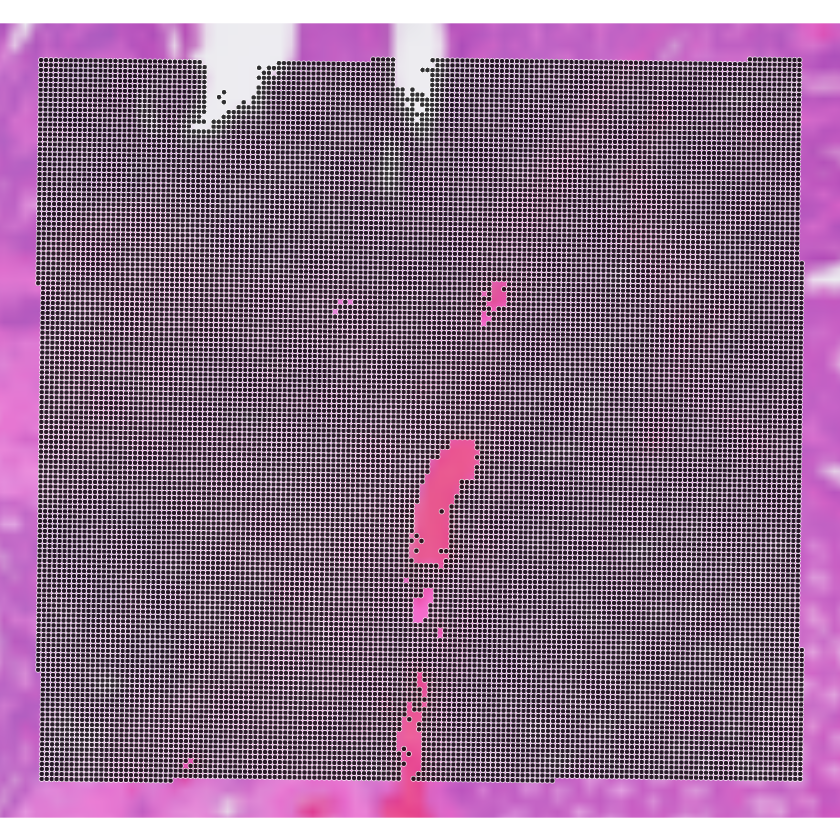

In [8]:
# Plot the 16µm binned spatial footprint
plotVisium(spe_bin_roi, zoom = TRUE)

Looking at this plot, we see exactly what is expected based on our work in the first notebook. The uniform grid of 16µm squares perfectly covers our selected ROI. Importantly, the empty "non-tissue" bins have been successfully removed, leaving visible gaps in the grid where there is no biological material present on the slide.

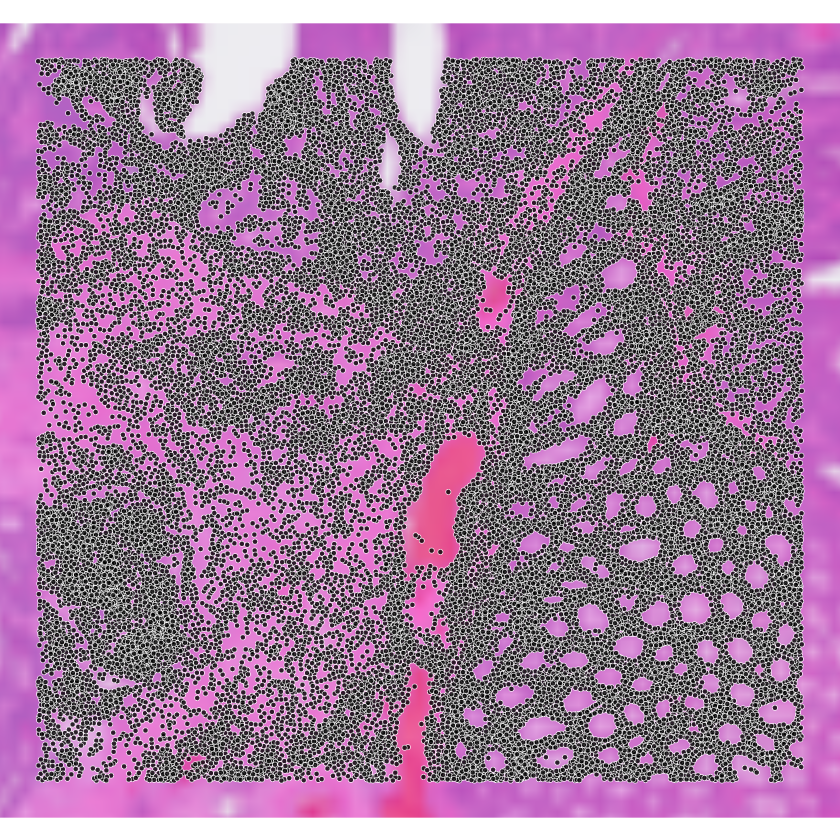

In [9]:
# Plot the pseudo-segmented cell footprint
plotVisium(spe_seg_roi, zoom = TRUE)

Here, we can clearly discriminate complex histological structures, such as the circular glandular crypts on the right side of the tissue, where cells naturally form rings around empty lumens.

Unlike the 16µm bins, we do not need to manually filter out the background here. Because the segmentation algorithm strictly requires a detected nucleus to draw a cell, empty non-tissue regions are natively excluded!

Furthermore, we can observe significantly more void space *within* the tissue itself. Large, rigid 16µm bins often overlap both the edge of a cell and an adjacent empty space, artificially filling in gaps. In contrast, segmentation wraps tightly around actual cells. This precision preserves truly acellular regions, like lumens, extracellular matrix, and tiny tissue tears, resulting in a much more faithful representation of the underlying histology.

### Comparing spatial gene expression

To fully appreciate the impact of cell segmentation, let's look beyond the physical tissue structure and map a biological signal onto both spatial layouts. We will visualize the expression of *PIGR*, a key marker gene associated with mucosal immunity that we explored in previous notebooks. 

In [10]:
# Plot PIGR expression on 16µm bins (using square points to represent bins)
p_vis <- plotVisium(
  spe_bin_roi, 
  annotate = "PIGR", 
  assay = "counts", 
  zoom = TRUE, 
  point_size = 1, 
  point_shape = 22)

# Plot PIGR expression on segmented cells (using circular points for centroids)
p_vis_seg <- plotVisium(
  spe_seg_roi, 
  annotate = "PIGR", 
  assay = "counts", 
  zoom = TRUE, 
  point_size = 1.5, 
  point_shape = 21)

Warning message in guide(title = annotate, order = 1, override.aes = list(col = NA, :
"Arguments in `...` must be used.
✖ Problematic argument:
• override.aes = list(col = NA, size = 3)
ℹ Did you misspell an argument name?"
Warning message in guide(title = annotate, order = 1, override.aes = list(col = NA, :
"Arguments in `...` must be used.
✖ Problematic argument:
• override.aes = list(col = NA, size = 3)
ℹ Did you misspell an argument name?"


>We can use `plot_layout(guides = "collect")` from the `patchwork` package to cleanly merge the two duplicate legends into one.

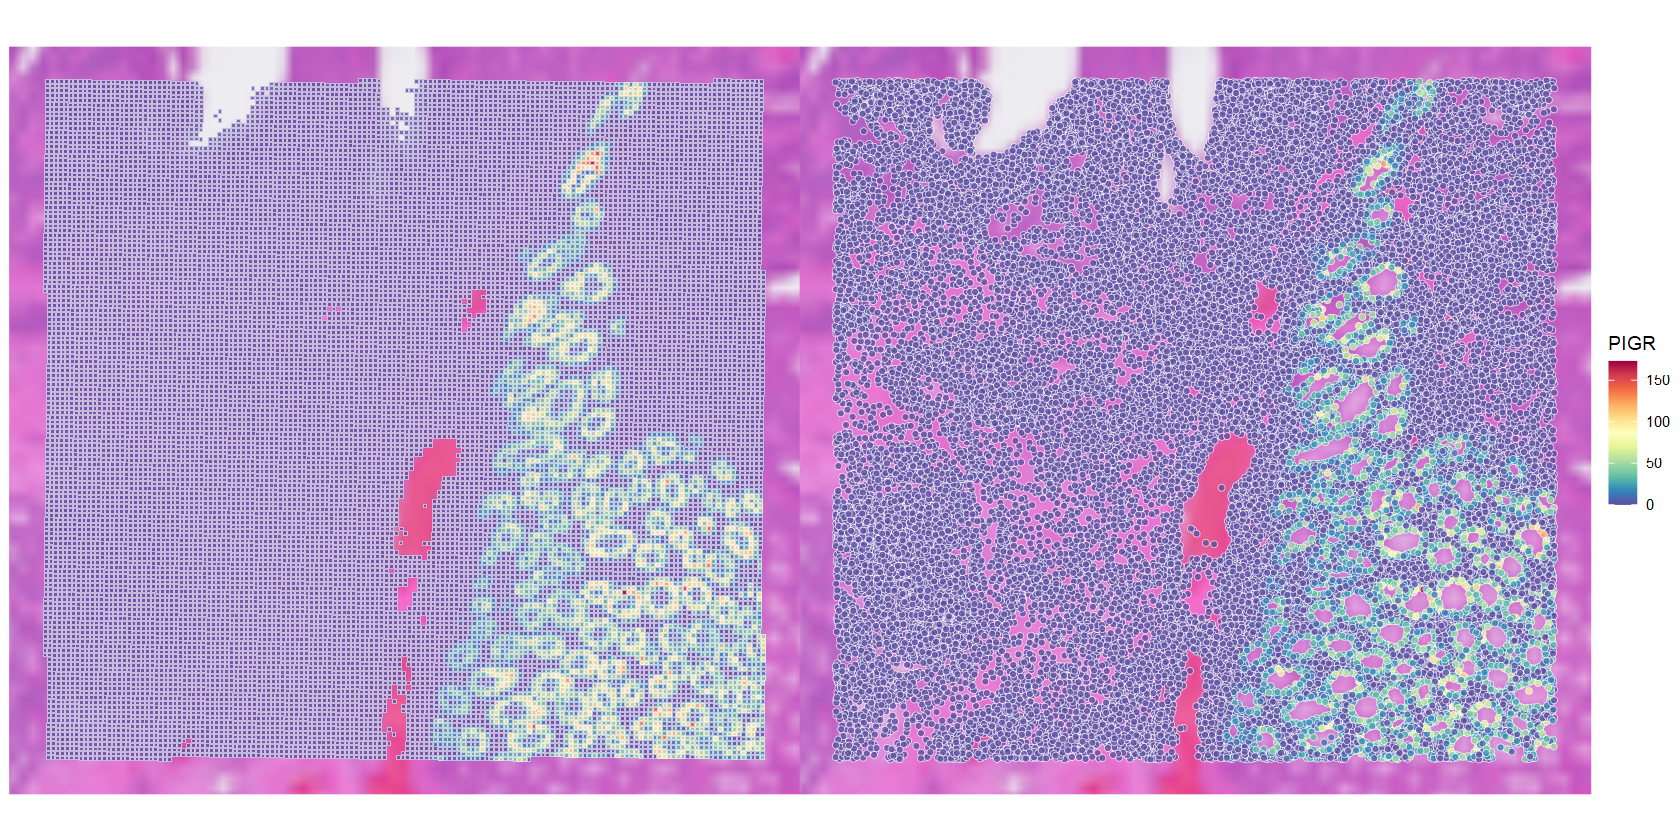

In [11]:
options(repr.plot.width = 14, repr.plot.height = 7)

# Display side-by-side and merge the duplicate legends
p_vis + p_vis_seg + plot_layout(guides = "collect")

By utilizing Visium HD segmented data, we obtain a highly detailed view of the tissue that breaks free from the artificial resolution limits of a rigid grid. When analyzing this `spe_seg` object, it is important to note that the $x$ and $y$ spatial coordinates plotted above represent only the centroids of each segmented cell. Because of this, zooming closely in on the plot reveals a scatter of uniform circles rather than the true biological shapes of the cells.

While we still have access to the full segmentation polygons (the exact cell boundaries), a standard `SpatialExperiment` object lacks a dedicated slot for complex geometries. Therefore, these boundary coordinates are stored within the `metadata` of our object, rather than in a native spatial slot.

## Converting to SpatialFeatureExperiment (SFE)

### Upgrading from SPE to SFE

To actually visualize and interact with the true cell boundaries rather than just their centroids, we need to upgrade our object into a `SpatialFeatureExperiment` (SFE). This specialized class (which we explored in the previous notebook with Xenium data) is designed specifically to handle complex polygon geometries natively.

First, we convert the base object.

In [12]:
# Convert SPE to SFE
sfe_seg_roi <- toSpatialFeatureExperiment(spe_seg_roi)

In [13]:
# Print the converted object to see its structure
sfe_seg_roi

class: SpatialFeatureExperiment 
dim: 39125 34874 
metadata(4): resouces spatialList cellseg boundary
assays(1): counts
rownames(39125): DDX11L2 MIR1302-2HG ... DEPRECATED_ENSG00000291096
  DEPRECATED_TRIM16L
rowData names(3): ID Symbol Type
colnames(34874): cellid_000080404-1 cellid_000080411-1 ...
  cellid_000189341-1 cellid_000189343-1
colData names(2): map sample_id
reducedDimNames(0):
mainExpName: Gene Expression
altExpNames(0):
spatialCoords names(2) : pxl_col_in_fullres pxl_row_in_fullres
imgData names(4): sample_id image_id data scaleFactor

unit:
Geometries:
colGeometries: centroids (POINT) 

Graphs:
sample01: 

### Attaching cell boundaries

The conversion function automatically took the basic _spatial coordinates_ and created a native geometry slot (`colGeometries: centroids (POINT)`). However, as indicated by `(POINT)`, these are still just simple dots.

The actual complex _cell boundaries_ are still sitting passively in the `metadata` list, entirely disconnected from the spatial mapping engine as an `sf` (simple features) object (`metadata(4): ... cellseg boundary`). Therefore, our next step is to extract the `cellseg` polygons from the metadata, filter them down to match our ROI, and formally register them as a proper `colGeometry`.

In [15]:
# Check the number of polygons hidden in the metadata
nrow(metadata(sfe_seg_roi)$cellseg)

[1] 220704

Because we previously subsetted our main object to a specific ROI, we must manually filter these hidden polygons so they perfectly match the 34,874 cells remaining in our dataset (`dim: 39125 34874`). Standard subsetting ignored the `metadata` slot, meaning `seg_full` still represents the entire uncropped slide. If we try to attach all ~220,700 polygons to our cropped object, R will throw a dimension mismatch error.

To reduce this data, we simply filter the rows of this metadata dataframe using the `in_roi_mask` TRUE/FALSE vector we generated earlier. Because both the spatial coordinates and these geometric polygons came from the exact same original object, we know they match perfectly row-for-row.

In [16]:
# Extract the full uncropped segmentations from the metadata
seg_full <- metadata(sfe_seg_roi)$cellseg

# Filter the polygons using our pre-existing ROI vector
seg_roi <- seg_full[in_roi_mask, ]

# Ensure the rownames strictly match our SFE object cells
rownames(seg_roi) <- colnames(sfe_seg_roi)

# Add the geometries to the native SFE slot
colGeometry(sfe_seg_roi, "cellSeg") <- seg_roi
# colGeometries(sfe_seg_roi)[["cellSeg"]] <- seg_roi

# Verify the geometry is now natively attached
colGeometries(sfe_seg_roi)

List of length 2
names(2): centroids cellSeg

In [17]:
# Verify the geometry contains exactly 34,874 polygons
nrow(colGeometry(sfe_seg_roi, "cellSeg"))

[1] 34874

### Alternative: importing cell boundaries from GeoJSON

To prove that the data stored in our metadata is identical to the raw files provided by SpaceRanger, we can manually import the `cell_segmentations.geojson` file from the `data/` directory and attach it as a new spatial layer.

Because we are importing this as a fresh, external file, we won't use our `in_roi_mask` shortcut. Instead, we will perform a true spatial filtering: we will read the file using the `sf` package, calculate the geometric centroid of every polygon, and explicitly filter them against our bounding box.

In [18]:
# Turn off spherical geometry strictness for flat image pixels!
sf_use_s2(FALSE)

# Read the raw GeoJSON file for CELLS
# - st_read() (from the 'sf' package) is the standard function used to 
#   import spatial vector data (like GeoJSON or shapefiles) into R.
geo_cell_full <- st_read(
  "data/Human_Colon_Cancer_P2/segmented_outputs/cell_segmentations.geojson")

# Strip the fake GPS coordinate system so sf treats it as a flat image.
st_crs(geo_cell_full) <- NA

# Extract the coordinates of their centroids
# - st_centroid() calculates the exact center point of each complex polygon.
# - st_coordinates() extracts the raw X and Y numerical values of those center 
#   points so we can easily filter them using standard mathematical logic (>=, <=).
# - Using st_geometry() prevents a minor warning about losing metadata 
#   attributes during the centroid calculation.
geo_cell_coords <- st_coordinates(st_centroid(st_geometry(geo_cell_full)))

geo_cell_roi <- geo_cell_full[
  geo_cell_coords[, 1] >= roi_visium[["xmin"]] &
  geo_cell_coords[, 1] <= roi_visium[["xmax"]] &
  geo_cell_coords[, 2] >= roi_visium[["ymin"]] &
  geo_cell_coords[, 2] <= roi_visium[["ymax"]], 
]

# Ensure the cell IDs match our object and clear the CRS
rownames(geo_cell_roi) <- colnames(sfe_seg_roi)
st_crs(geo_cell_roi) <- NA_crs_

# Attach this to our SFE object under a NEW geometry name
colGeometry(sfe_seg_roi, "cellSegGeoJSON") <- geo_cell_roi

# Verify all three (3) geometries are now attached
colGeometries(sfe_seg_roi)

Spherical geometry (s2) switched off



Reading layer `cell_segmentations' from data source 
  `C:\Users\Sébastien\Documents\data_science\bioinformatics\intro-spatial-transcriptomics-training\data\Human_Colon_Cancer_P2\segmented_outputs\cell_segmentations.geojson' 
  using driver `GeoJSON'
Simple feature collection with 220704 features and 1 field
Geometry type: POLYGON
Dimension:     XY
Bounding box:  xmin: 40587.5 ymin: -28.8 xmax: 65202.7 ymax: 22701
Geodetic CRS:  WGS 84


List of length 3
names(3): centroids cellSeg cellSegGeoJSON

In [19]:
# Verify the GeoJSON geometry matches our 34,874 cell count perfectly
nrow(colGeometry(sfe_seg_roi, "cellSegGeoJSON"))

[1] 34874

As we can see from the console output, the raw GeoJSON file initially loaded all **~220,700** polygons for the entire uncropped slide. By explicitly calculating the true geometric centroid of every single polygon and mathematically filtering them against our bounding box, we successfully cropped the file down to exactly **34,874** cells, perfectly matching the metadata we extracted in the previous step.

*(Note: If we had carelessly attempted to filter the GeoJSON using a TRUE/FALSE vector generated directly from our current 34,874-row `spatialCoords()` matrix, R would have silently recycled the shorter vector, assigning completely mismatched coordinates without throwing an error.)*

Because we performed this filtering using explicit spatial math, we have successfully proven that the raw GeoJSON coordinates align perfectly with our object's internal metadata. We can further verify this equivalence by printing the first few rows of both geometries to confirm they contain identically structured `MULTIPOLYGON` coordinate arrays.

In [20]:
# Print the first few rows of the metadata-derived boundaries
colGeometry(sfe_seg_roi, "cellSeg") |> as.data.frame() |> head()

# Print the first few rows of the GeoJSON-derived boundaries
colGeometry(sfe_seg_roi, "cellSegGeoJSON") |> as.data.frame() |> head()

,cell_id,geometry
,<chr>,<POLYGON>
cellid_000080404-1,cellid_000080404-1,"POLYGON ((49399.2 7797.2, 4..."
cellid_000080411-1,cellid_000080411-1,"POLYGON ((49106.9 9466.2, 4..."
cellid_000080412-1,cellid_000080412-1,"POLYGON ((49116.2 9868.2, 4..."
cellid_000080429-1,cellid_000080429-1,"POLYGON ((49377.1 7811.6, 4..."
cellid_000080439-1,cellid_000080439-1,"POLYGON ((49370.3 7767.6, 4..."
cellid_000080443-1,cellid_000080443-1,"POLYGON ((49003.7 10641, 49..."


,cell_id,geometry
,<int>,<POLYGON>
cellid_000080404-1,80404,"POLYGON ((49399.2 7797.2, 4..."
cellid_000080411-1,80411,"POLYGON ((49106.9 9466.2, 4..."
cellid_000080412-1,80412,"POLYGON ((49116.2 9868.2, 4..."
cellid_000080429-1,80429,"POLYGON ((49377.1 7811.6, 4..."
cellid_000080439-1,80439,"POLYGON ((49370.3 7767.6, 4..."
cellid_000080443-1,80443,"POLYGON ((49003.7 10641, 49..."


Let's now visually confirm they are mathematically identical. Because our current ROI is still too dense to see individual cells clearly, we will first create a highly zoomed-in crop of our `sfe_seg_roi` object. We can thus use the base `plot()` function to stack the spatial geometries directly on top of one another (blue fill, red outlines, and black centroids).

In [21]:
# Create a highly zoomed-in ROI
roi_zoomed <- c(
  xmin = 54500, 
  xmax = 55000, 
  ymin = 12500, 
  ymax = 13000)

# Extract coordinates once for cleaner code
sfe_coords <- spatialCoords(sfe_seg_roi)

# Create a logical mask (TRUE for cells inside the ZOOM, FALSE otherwise)
sfe_zoomed_mask <- 
  sfe_coords[, 1] >= roi_zoomed[["xmin"]] & 
  sfe_coords[, 1] <= roi_zoomed[["xmax"]] & 
  sfe_coords[, 2] >= roi_zoomed[["ymin"]] & 
  sfe_coords[, 2] <= roi_zoomed[["ymax"]]

# Subset the SFE object elegantly using the mask
sfe_zoomed <- sfe_seg_roi[, sfe_zoomed_mask]

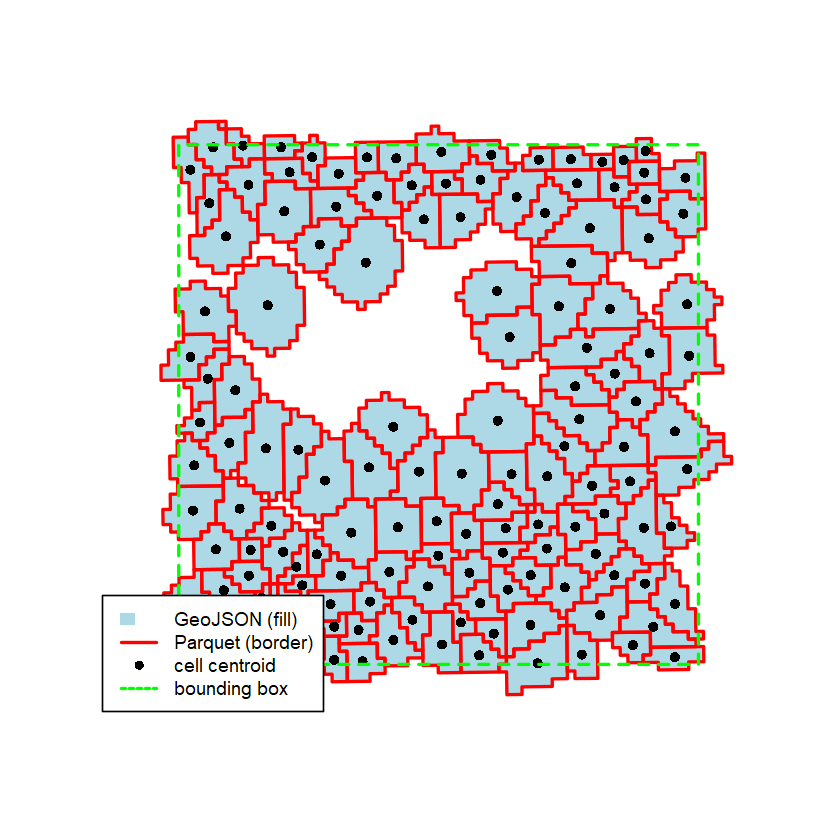

In [22]:
options(repr.plot.width = 7, repr.plot.height = 7)

# Plot the GeoJSON cell polygons (solid light blue fill, no borders)
plot(
  st_geometry(colGeometry(sfe_zoomed, "cellSegGeoJSON")), 
  col = "lightblue", 
  border = NA)

# Overlay the Parquet metadata polygons (red borders only)
plot(
  st_geometry(colGeometry(sfe_zoomed, "cellSeg")), 
  col = NA, 
  border = "red", 
  lwd = 2, 
  add = TRUE)

# Overlay the exact centroids (as black dots)
plot(
  st_geometry(colGeometry(sfe_zoomed, "centroids")), 
  col = "black", 
  pch = 16, 
  cex = 1, 
  add = TRUE)

# Add the Bounding Box (Green dashed line)
# Convert the coordinates of our zoomed ROI into an actual drawable polygon
roi_bbox <- st_bbox(roi_zoomed)
roi_poly <- st_as_sfc(roi_bbox)

plot(roi_poly, border = "green", lwd = 2, lty = "aa", add = TRUE)

# Add a custom legend to the bottom left corner
legend(
  "bottomleft", 
  inset = 0.01,                          # Nudges the legend 1% inward from the edge
  legend = c("GeoJSON (fill)", "Parquet (border)", "cell centroid", "bounding box"), 
  fill = c("lightblue", NA, NA, NA),     # Only the first item gets a color fill box
  border = c("transparent", NA, NA, NA), # Remove the default black outline around the fill box
  lty = c(NA, 1, NA, 2),                 # Only the second item gets a drawn line
  col = c(NA, "red", "black", "green"),  # Colors for the line and the point
  pch = c(NA, NA, 16, NA),               # Only the third item gets a drawn point
  lwd = c(NA, 2, NA, 2),                 # Line thickness for the red border
  cex = 0.9,                             # Slightly scale down the text size
)

The red outlines (derived from the parquet metadata) perfectly hug the blue fill (derived from the GeoJSON). This definitively proves that both file formats contain the exact same spatial data. Additionally, we can clearly visualize how the centroid coordinates map precisely into the center of these complex polygon structures.

Also, notice that there are no cut, sliced, or "open" polygons on the edges of our plot. If we had performed a raw spatial intersection (like a cookie-cutter), the polygons sitting on the border would have been sliced exactly in half. Instead, when we subsetted our main object using standard bracket notation (`sfe_zoomed <- sfe_seg_roi[, ...]`), the `SpatialFeatureExperiment` package simply filtered the geometries by their Row IDs to match the surviving cells. Because our filtering rule was based purely on whether a cell's *centroid* fell inside the box, the package kept the *entire* intact polygon for every surviving cell, that's why we can actually see the intact cell borders spilling out over the bounding box edge! This powerful, non-destructive behavior is exactly why we went through the effort of formally registering our polygons into the `colGeometries` slots.

Finally, and most importantly, we can see the fundamental limits of this spatial technology. Unlike true single-cell techniques (like Xenium) which draw fluid, organic cell membranes, the highly jagged borders here visibly betray the fact that Visium HD "cells" are simply mathematical approximations built by rigidly stitching together discrete 2x2µm squares.

### Integrating nuclear segmentations

In spatial transcriptomics workflows, incorporating complementary morphological data, such as the nuclear boundaries identified via DAPI staining, is highly valuable for downstream spatial analysis.

When importing the `nucleus_segmentations.geojson` file, the raw dataset again contains over 220,000 polygons. Re-evaluating the spatial overlaps independently for the nuclei introduces a risk of dimension mismatch at the border of our ROI; for instance, a cell's coordinates might fall inside the ROI while its eccentric nucleus physically falls outside.

Because the cell and nucleus outputs from the Space Ranger pipeline maintain a strict 1:1 row alignment, we avoid this independent coordinate filtering by reusing our original `in_roi_mask` logical vector. This enforces dimensional consistency, guaranteeing the extraction of the exact same 34,874 polygons and perfectly aligning the nuclear geometries with our existing cellular dataset.

In [23]:
# Read the raw GeoJSON file for NUCLEI
nuc_geo <- st_read(
  "data/Human_Colon_Cancer_P2/segmented_outputs/nucleus_segmentations.geojson")

# REUSE the exact same boolean vector we created for the cells!
nuc_geo_cropped <- nuc_geo[in_roi_mask, ]
st_crs(nuc_geo_cropped) <- NA

# Ensure the rownames precisely match our SFE object's cell column names
rownames(nuc_geo_cropped) <- colnames(sfe_seg_roi)

# Register the nuclei geometries in our main object
colGeometry(sfe_seg_roi, "nucleusSeg") <- nuc_geo_cropped

Reading layer `nucleus_segmentations' from data source 
  `C:\Users\Sébastien\Documents\data_science\bioinformatics\intro-spatial-transcriptomics-training\data\Human_Colon_Cancer_P2\segmented_outputs\nucleus_segmentations.geojson' 
  using driver `GeoJSON'
Simple feature collection with 220704 features and 1 field
Geometry type: POLYGON
Dimension:     XY
Bounding box:  xmin: 40590.3 ymin: 0.4 xmax: 65202.3 ymax: 22701
Geodetic CRS:  WGS 84


To visually verify the integration of our nuclear data, we must update our highly-zoomed `sfe_zoomed` object so that it inherits the newly added geometries. Rather than recalculating spatial coordinate bounds, we elegantly subset the updated parent object (`sfe_seg_roi`) using the exact cell identifiers (`colnames`) already isolated in our previous zoom.

Because the nuclear polygons were properly registered as `colGeometries` within the parent object `sfe_seg_roi`, the `SpatialFeatureExperiment` architecture automatically co-registers and extracts both the cellular and nuclear geometries for those specific cells in tandem. We can now overlay the cell boundaries, the internal nuclear boundaries, and the cellular centroids to confirm strict spatial alignment.

In [24]:
# Regenerate the highly-zoomed object so it inherits the newly registered nuclear geometries.
sfe_zoomed <- sfe_seg_roi[, colnames(sfe_zoomed)]

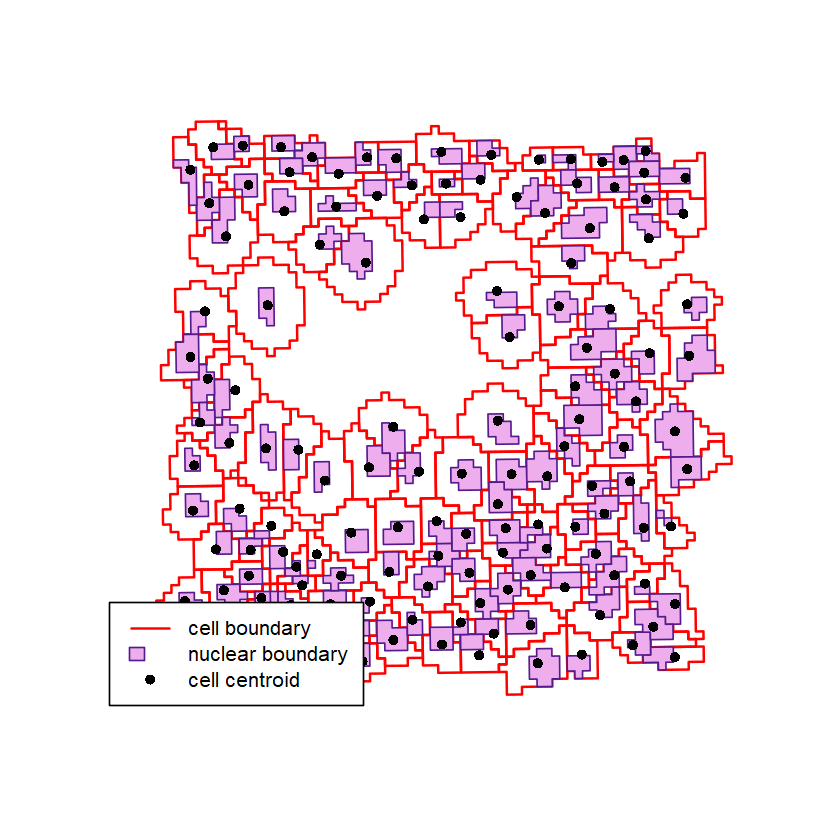

In [25]:
# Plot the Cell boundaries (Red Outlines, No Fill)
plot(
  st_geometry(colGeometry(sfe_zoomed, "cellSeg")), 
  border = "red", 
  col = NA, 
  lwd = 1.5, )

# Add the Nuclear boundaries (Light Blue Fill, Blue Outlines)
plot(
  st_geometry(colGeometry(sfe_zoomed, "nucleusSeg")), 
  col = "plum2", 
  border = "purple4", 
  add = TRUE, )

# Add the Cell Centroids (Black Dots)
plot(
  st_centroid(st_geometry(colGeometry(sfe_zoomed, "cellSeg"))),
  col = "black", 
  pch = 16, 
  add = TRUE, )

# Add a custom legend
legend(
  "bottomleft", 
  inset = 0.02, 
  legend = c("cell boundary", "nuclear boundary", "cell centroid"), 
  fill = c(NA, "plum2", NA), 
  border = c("transparent", "purple4", NA), 
  lty = c(1, NA, NA), 
  col = c("red", NA, "black"), 
  pch = c(NA, NA, 16), 
  lwd = c(1.5, NA, NA), )

Notice how the black dots (cell centroids) rarely sit perfectly inside the violet nuclei. This biological reality visually proves why a cell and its nucleus have different spatial coordinates, and exactly why we had to safely reuse our `in_roi_mask` vector rather than recalculating bounding box intersections.

## Direct import and spatial feature analysis

### Direct import via wrapper

Up to this point, we manually constructed our `SpatialFeatureExperiment` object and parsed the GeoJSON polygons ourselves to thoroughly understand how spatial data is anchored to the gene expression matrix.

However, `SpatialFeatureExperiment` provides a highly convenient wrapper function, `readVisiumHD()`, which can automatically parse the 10x Genomics outputs, including the high-resolution segmentations, and assemble the object for us in a single step. We will import the `filtered` data and instruct the function to automatically use Gene Symbols.

In [27]:
# The wrapper function requires the path to the parent 'outs/' directory,
# as it will automatically search for the 'segmented_outputs' subfolder.
parent_outs_dir <- dirname(segmented_dir)

sfe_seg <- readVisiumHD(
  data_dir = parent_outs_dir, 
  # sample_id = "VisiumHD_Segmented", 
  use_cellseg = TRUE,   # Automatically attaches Space Ranger polygon boundaries
  data = "filtered",    # Use the QC-passed matrix
  type = "HDF5", 
  flip = "image",       # (CRITICAL: Bypasses a bug when handling polygons)
  unit = "micron",      # Converts polygon coordinates into true micrometers
  row.names = "symbol", # Automatically uses human-readable Gene Symbols!
)

>>> 10X VisiumHD data will be loaded: segmented_outputs


>>> Converting pixels to microns



In [28]:
# Print the imported object to verify its structure
sfe_seg

class: SpatialFeatureExperiment 
dim: 18132 220703 
metadata(1): Samples
assays(1): counts
rownames(18132): SAMD11 NOC2L ... MT-ND6 MT-CYB
rowData names(3): ID Symbol Type
colnames(220703): 3 4 ... 268813 268814
colData names(3): Sample Barcode sample_id
reducedDimNames(0):
mainExpName: NULL
altExpNames(0):
spatialCoords names(2) : pxl_col_in_fullres pxl_row_in_fullres
imgData names(4): sample_id image_id data scaleFactor

unit: micron
Geometries:
colGeometries: centroids (POINT), cellSeg (POLYGON), nucSeg (POLYGON) 

Graphs:
sample01: 

The `raw` matrix (used at the beginning of the notebook) retains the entire reference genome (39,125 features), whereas the `filtered` matrix (used here) excludes genes with zero expression across the tissue, leaving 18,132 genes. Additionally, out of nearly a quarter-million visually segmented polygons, the Space Ranger pipeline discarded exactly one cell during its QC step (220,704 vs. 220,703 cells).

Also note that, to reuse our established ROI, we must scale its bounds to **microns (µm)**. The `unit = "micron"` parameter automatically translated the object's spatial coordinates using the `microns_per_pixel` factor (~0.2737) from `scalefactors_json.json`, although legacy pixel-based column names remain.

Crucially, by using the `use_cellseg = TRUE` argument during import, the wrapper automatically detected and attached both the cellular boundaries (`cellSeg`) and the internal nuclear boundaries (`nucSeg`) directly into the object's `colGeometries`. This deep integration enables us to simultaneously crop the expression matrix and all associated geometric layers via a single logical spatial filter.

In [29]:
# Convert the pixel-based ROI to microns using the scale factor
microns_per_pixel <- 0.2737012522439323
roi_visium_micron <- roi_visium * microns_per_pixel

# Identify which cells fall within our micron-scaled ROI
coords_micron <- spatialCoords(sfe_seg)

in_roi_micron_mask <- 
  coords_micron[, 1] >= roi_visium_micron["xmin"] & 
  coords_micron[, 1] <= roi_visium_micron["xmax"] & 
  coords_micron[, 2] >= roi_visium_micron["ymin"] & 
  coords_micron[, 2] <= roi_visium_micron["ymax"]

# Subset the SFE object directly (this automatically subsets the segmentation polygons too!)
sfe_seg_roi <- sfe_seg[, in_roi_micron_mask]

In [30]:
# Print the cropped object
sfe_seg_roi

class: SpatialFeatureExperiment 
dim: 18132 34874 
metadata(1): Samples
assays(1): counts
rownames(18132): SAMD11 NOC2L ... MT-ND6 MT-CYB
rowData names(3): ID Symbol Type
colnames(34874): 80404 80411 ... 189341 189343
colData names(3): Sample Barcode sample_id
reducedDimNames(0):
mainExpName: NULL
altExpNames(0):
spatialCoords names(2) : pxl_col_in_fullres pxl_row_in_fullres
imgData names(4): sample_id image_id data scaleFactor

unit: micron
Geometries:
colGeometries: centroids (POINT), cellSeg (POLYGON), nucSeg (POLYGON) 

Graphs:
sample01: 

To visualize the structural data seamlessly integrated by the wrapper, we will recreate our highly localized spatial zoom. Because our primary object (`sfe_seg_roi`) is now scaled in physical microns, we must first apply our `microns_per_pixel` scale factor to our secondary pixel-based bounding box (`roi_zoomed`).

By applying this scaled spatial mask, the `SpatialFeatureExperiment` architecture instantly subsets the expression matrix while automatically co-registering and cropping both geometric layers. It is important to note that the wrapper function inherently assigned the identifier `nucSeg` to the nuclear boundaries. We can now render these multi-layered geometries using an updated color palette to visually verify their precise structural alignment.

In [31]:
# Convert the pixel ROI to microns
roi_zoomed_micron <- roi_zoomed * microns_per_pixel

# Extract coordinates from our micron-scaled primary object
# (we need a masking vector of length = 34,874)
sfe_coords <- spatialCoords(sfe_seg_roi)

# Create a logical mask using the micron bounds
sfe_zoomed_mask <- 
  sfe_coords[, 1] >= roi_zoomed_micron[["xmin"]] & 
  sfe_coords[, 1] <= roi_zoomed_micron[["xmax"]] & 
  sfe_coords[, 2] >= roi_zoomed_micron[["ymin"]] & 
  sfe_coords[, 2] <= roi_zoomed_micron[["ymax"]]

# Subset the SFE object elegantly (automatically cropping cellSeg and nucSeg)
sfe_zoomed <- sfe_seg_roi[, sfe_zoomed_mask]

>We deliberately extract our spatial coordinates from the intermediate `sfe_seg_roi` object rather than the full slide. This lighter, optimized dataset will serve as the core foundation for all downstream analysis and is the final object we will save to disk.

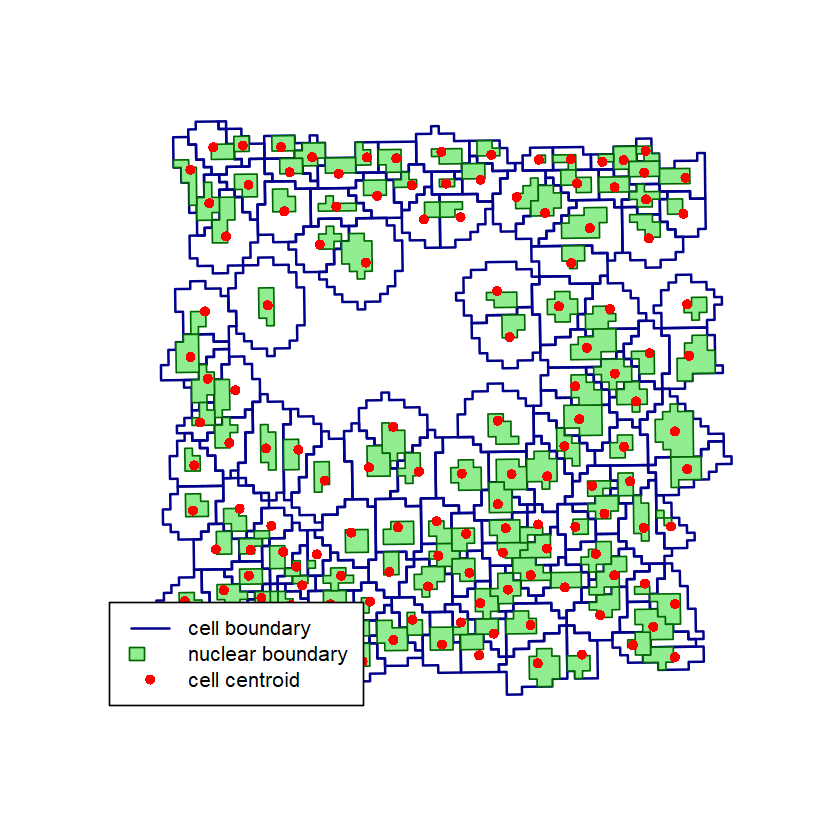

In [32]:
# Plot the Cell boundaries (Dark Blue Outlines, No Fill)
plot(
  st_geometry(colGeometry(sfe_zoomed, "cellSeg")), 
  border = "darkblue", 
  col = NA, 
  lwd = 1.5, )

# Add the Nuclear boundaries (Light Green Fill, Dark Green Outlines)
# Note: The wrapper automatically assigned the name "nucSeg"
plot(
  st_geometry(colGeometry(sfe_zoomed, "nucSeg")), 
  col = "lightgreen", 
  border = "darkgreen", 
  add = TRUE, )

# Add the Cell Centroids (Red Dots)
plot(
  st_centroid(st_geometry(colGeometry(sfe_zoomed, "cellSeg"))),
  col = "red", 
  pch = 16, 
  add = TRUE, )

# Add a custom legend
legend(
  "bottomleft", 
  inset = 0.02, 
  legend = c("cell boundary", "nuclear boundary", "cell centroid"), 
  fill = c(NA, "lightgreen", NA), 
  border = c("transparent", "darkgreen", NA), 
  lty = c(1, NA, NA), 
  col = c("darkblue", NA, "red"), 
  pch = c(NA, NA, 16), 
  lwd = c(1.5, NA, NA), 
)

### Morphometrics: calculating exact physical area

In earlier spatial technologies, calculating cell area required estimating the number of underlying grid spots or bins. However, because our automated wrapper imported the exact organic polygons as `sf` geometries and automatically scaled our entire coordinate system using the `unit = "micron"` parameter, we no longer need to rely on bin-based approximations. We can instantly calculate the true, mathematically precise physical area (in square microns, µm²) of every cell and nucleus using the `st_area()` function.

In [33]:
# Calculate exact polygon area (now natively in square microns)
sfe_seg_roi$cell_area_um2 <- st_area(colGeometry(sfe_seg_roi, "cellSeg"))
sfe_seg_roi$nuc_area_um2 <- st_area(colGeometry(sfe_seg_roi, "nucSeg"))

We can then test a classic biological hypothesis: do larger cells, or specifically, larger nuclei, yield higher sequencing depth? By plotting both our calculated cell areas and nuclear areas against the total transcript counts, we can investigate whether either of these structural features correlates with overall transcriptional activity.

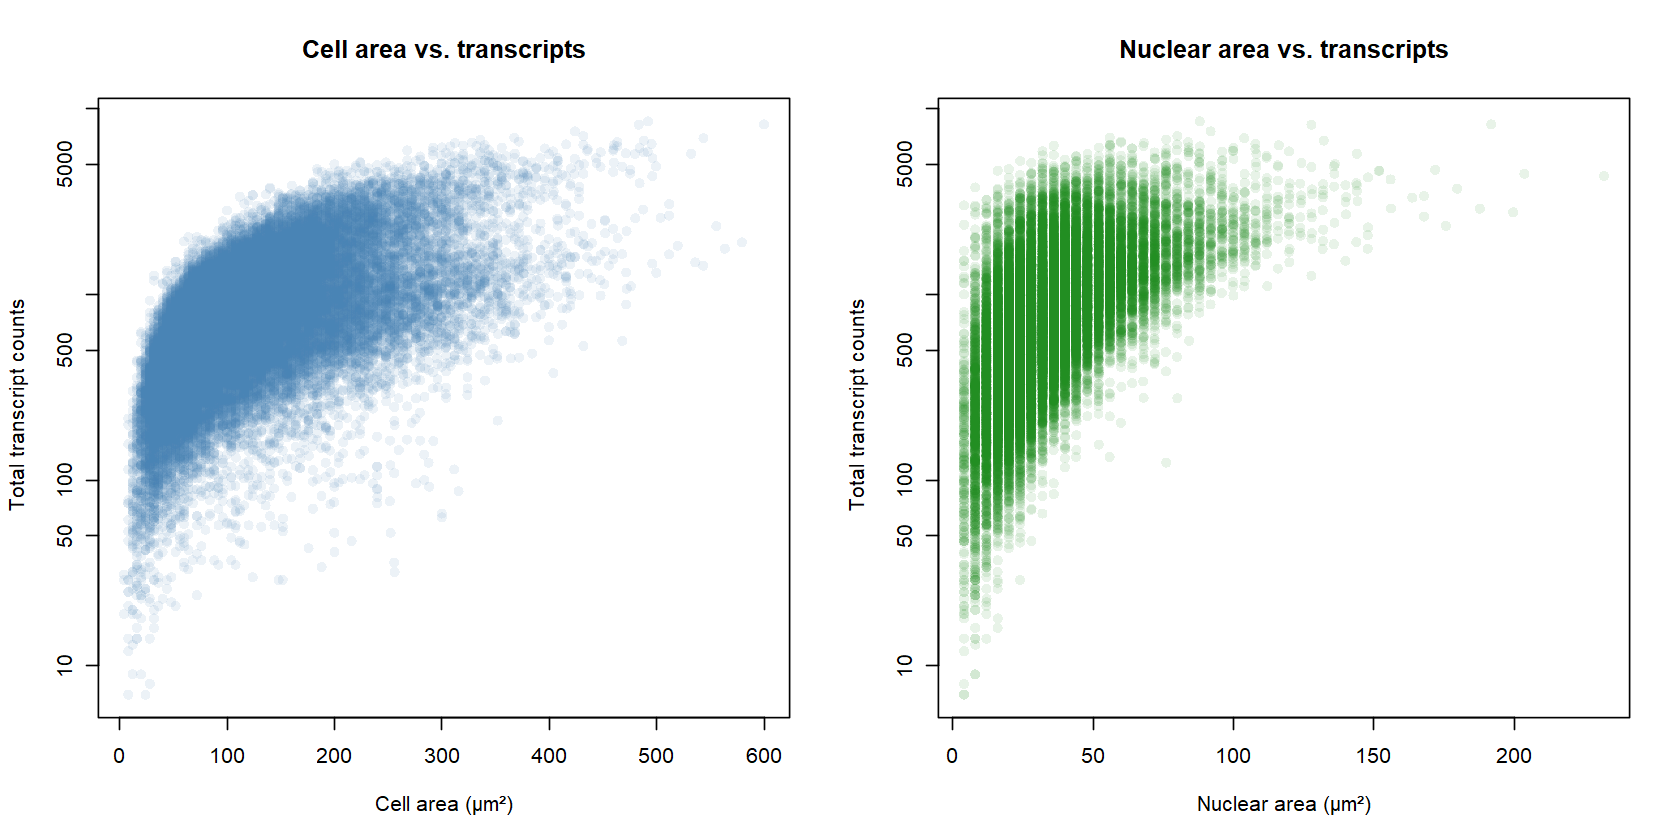

In [34]:
options(repr.plot.width = 14, repr.plot.height = 7)

# Set up plotting layout (1 row, 2 columns) for side-by-side comparison
par(mfrow = c(1, 2))

# Plot 1: cell area vs total counts
plot(
  x = sfe_seg_roi$cell_area_um2, 
  y = colSums(counts(sfe_seg_roi)), 
  log = "y", 
  xlab = "Cell area (µm²)", 
  ylab = "Total transcript counts",
  main = "Cell area vs. transcripts",
  pch = 16, 
  col = adjustcolor("steelblue", .1),  # alpha/transparency
)

# Plot 2: Nuclear Area vs Total Counts
plot(
  x = sfe_seg_roi$nuc_area_um2, 
  y = colSums(counts(sfe_seg_roi)), 
  log = "y", 
  xlab = "Nuclear area (µm²)", 
  ylab = "Total transcript counts",
  main = "Nuclear area vs. transcripts",
  pch = 16, 
  col = adjustcolor("forestgreen", .1),
)

# Reset plotting layout
par(mfrow = c(1, 1))

### Visualizing features on complex geometries

As our scatter plots demonstrated, larger cells and larger nuclei generally capture a higher total number of transcripts. However, extracting global mathematical correlations is only the beginning of spatial analysis. The true power of the `SpatialFeatureExperiment` architecture lies in its ability to map molecular and morphological features directly onto physical structures in their native context.

Because our polygons are officially registered within the SFE object, we can take full advantage of specialized wrapper functions like `plotSpatialFeature()` from the `Voyager` package. This allows us to effortlessly project any metadata column or gene expression profile directly onto the organic cell boundaries.

In [35]:
options(repr.plot.width = 7, repr.plot.height = 7)

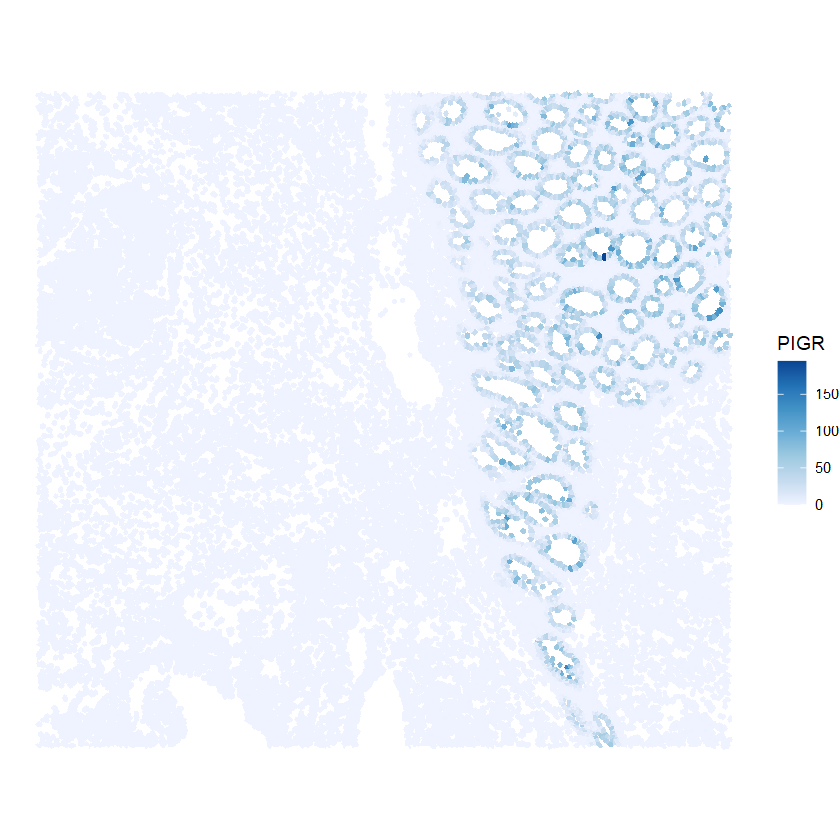

In [36]:
# Plot the expression of PIGR on each segmented cell
plotSpatialFeature(
  sfe_seg_roi, 
  colGeometryName = "cellSeg", 
  features = "PIGR", 
  exprs_values = "counts")

By mapping expression onto true segmented polygons rather than abstract center points, the native tissue morphology is perfectly preserved. The glandular structures of the colon are clearly delineated by the continuous layer of epithelial cells expressing *PIGR*. If we look closely at these highly expressed regions, the individual, organically shaped cell boundaries are distinctly visible.

We can also take the exact physical cell area we just calculated (`cell_area_um2`) and map it spatially across the tissue. First, we will quickly re-apply our `colnames` subsetting trick to ensure our highly-zoomed object inherits this newly calculated metadata from the parent object. Then, we can plot the feature to see exactly where the largest and smallest cells are physically located.

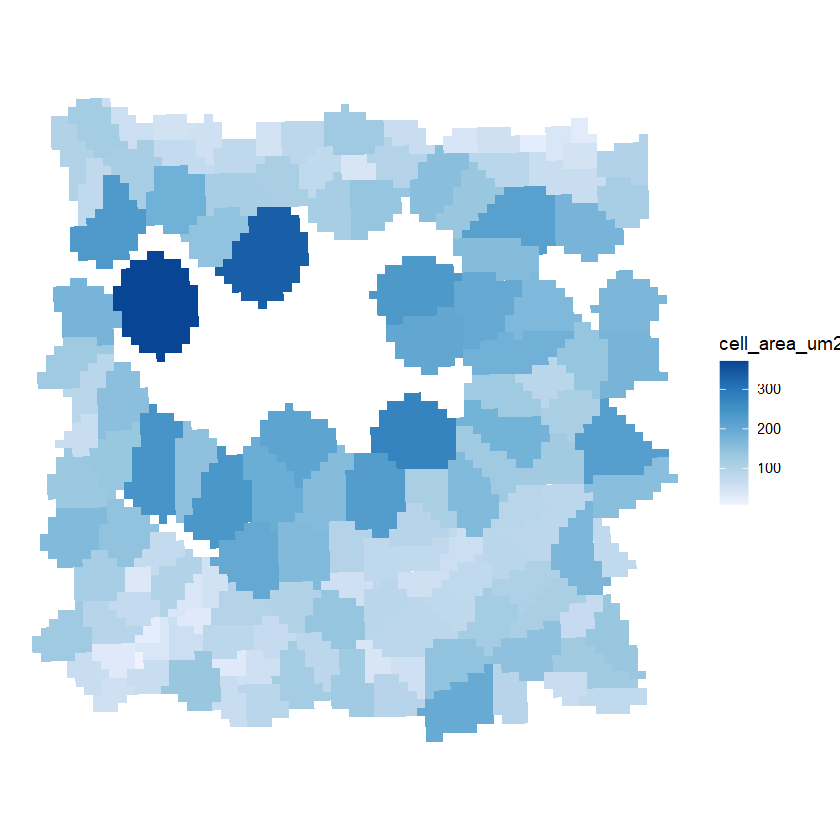

In [37]:
# Update our highly-zoomed object so it inherits the newly calculated area metadata
sfe_zoomed <- sfe_seg_roi[, colnames(sfe_zoomed)]

# Now we can plot the area directly on the cell boundaries
plotSpatialFeature(
  sfe_zoomed, 
  colGeometryName = "cellSeg", 
  features = "cell_area_um2")

## Finalizing the object

### Saving the object

In our first workflow, we used `saveHDF5SummarizedExperiment` to safely store our standard `SpatialExperiment` object on disk. However, as we have seen, our new `SpatialFeatureExperiment` architecture is significantly more complex, as it includes multiple mathematical geometry layers (`cellSeg`, `nucSeg`). Standard serialization functions struggle to properly write and re-import these `sf` polygons.

To solve this, we will once again use the `alabaster.sfe` package. As we learned in the Xenium workflow, this package implements a robust, modular, language-agnostic format designed specifically to serialize complex `SpatialFeatureExperiment` objects to disk (based on the [ArtifactDB project](https://github.com/ArtifactDB)).

>For the rest of the exercises in this course, we will use this specific Visium HD segmented object as our primary dataset. However, we could substitute it with the [VisiumHD binned object](./01-data_ingestion_SpatialExperiment_object.ipynb) or the [Xenium object](./02-data_ingestion_SpatialFeatureExperiment_object.ipynb) to compare how the different architectures influence downstream results!

In [38]:
# Define the output directory path
out_path <- "output/sfe_visiumhd_segmented"

# Remove any existing directory to prevent overwriting errors
if (dir.exists(out_path)) {
  unlink(out_path, recursive = TRUE)
}

# Save the SFE object (and all its spatial geometries) modularly to disk
alabaster.sfe::saveObject(sfe_seg_roi, out_path)

>>> Saving SpatialExperiment

>>> Saving colgeometries



As we saw in the previous notebook, `alabaster.sfe` saves the data as a highly-organized directory.

In [39]:
# Inspect the modular directory structure created by alabaster.sfe
fs::dir_tree(out_path)

output/sfe_visiumhd_segmented
├── assays
│   ├── 0
│   │   ├── matrix.h5
│   │   └── OBJECT
│   └── names.json
├── colgeometries
│   ├── 0
│   │   ├── map.parquet
│   │   └── OBJECT
│   ├── 1
│   │   ├── map.parquet
│   │   └── OBJECT
│   ├── 2
│   │   ├── map.parquet
│   │   └── OBJECT
│   └── names.json
├── column_data
│   ├── basic_columns.h5
│   └── OBJECT
├── coordinates
│   ├── array.h5
│   └── OBJECT
├── images
│   ├── 0
│   │   ├── image.tiff
│   │   ├── image.tiff.aux.xml
│   │   └── OBJECT
│   ├── 1
│   │   ├── image.tiff
│   │   ├── image.tiff.aux.xml
│   │   └── OBJECT
│   └── mapping.h5
├── OBJECT
├── other_data
│   ├── list_contents.json.gz
│   └── OBJECT
├── row_data
│   ├── basic_columns.h5
│   └── OBJECT
└── _environment.json


### Clearing the environment

Before moving on to the next notebook, it is highly recommended to clear our R workspace. Because spatial transcriptomic datasets and their associated geometries are massive, clearing the environment frees up the computer's RAM. It also ensures we are starting the next notebook from a completely clean slate, preventing any old variables from leaking into our new analysis.

*(Note: Depending on the code editor, it is also good practice to completely restart the R Kernel/Session from the menu bar before opening the next notebook).*

In [40]:
# Clear all variables from the R environment
rm(list = ls())

# Run garbage collection to aggressively free up RAM
gc()

,used,(Mb),gc trigger,(Mb),max used,(Mb)
Ncells,12951871,691.8,40527920,2164.5,50659900,2705.6
Vcells,28288240,215.9,177991682,1358.0,222489602,1697.5
